# Lab 2 — Isolation Forest vs Autoencoder with Embeddings

This notebook provides a self-contained login-anomaly example aligned with the lecture:

- **Isolation Forest** detects rare feature-space outliers.
- **Autoencoder with embeddings** learns normal behavioral combinations.
- The final section compares the models and inspects disagreements.

The synthetic scenario is related to **MITRE ATT&CK T1078 (Valid Accounts)** and **T1110 (Brute Force)**.


> **Interpretation guidance:** Explanatory comments are included after each results section to help connect the metrics and visualizations to SOC decision-making.


In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, precision_recall_fscore_support
)
from sklearn.decomposition import PCA

import keras
from keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Keras backend:", keras.backend.backend())


Keras backend: torch


## 1. Generate synthetic login telemetry

Normal records follow stable user, device, country and working-hour patterns. Attack records introduce unusual combinations such as late-night access, new countries, unknown devices and repeated failures.


In [2]:
N_NORMAL = 3800
N_ATTACK = 160

users = ["analyst01", "analyst02", "finance01", "developer01", "admin01"]
usual_country = {
    "analyst01": "IL", "analyst02": "IL", "finance01": "IL",
    "developer01": "IL", "admin01": "IL"
}
usual_device = {
    "analyst01": "managed_laptop", "analyst02": "managed_laptop",
    "finance01": "managed_laptop", "developer01": "developer_workstation",
    "admin01": "admin_workstation"
}

rows = []
for _ in range(N_NORMAL):
    user = np.random.choice(users, p=[0.25, 0.20, 0.20, 0.25, 0.10])
    rows.append({
        "user": user,
        "country": usual_country[user],
        "device": usual_device[user],
        "protocol": np.random.choice(["HTTPS", "VPN", "SSH"], p=[0.60, 0.32, 0.08]),
        "hour": int(np.clip(np.random.normal(12.5, 2.5), 6, 21)),
        "failed_attempts": np.random.poisson(0.25),
        "distance_km": abs(np.random.normal(8, 12)),
        "session_minutes": max(1, np.random.gamma(3.5, 12)),
        "bytes_out_mb": max(0.1, np.random.lognormal(2.0, 0.6)),
        "is_attack": 0
    })

for _ in range(N_ATTACK):
    user = np.random.choice(users)
    rows.append({
        "user": user,
        "country": np.random.choice(["RU", "CN", "SG", "US", "DE"]),
        "device": np.random.choice(["unknown", "mobile", "unmanaged_laptop"]),
        "protocol": np.random.choice(["HTTPS", "VPN", "SSH"]),
        "hour": np.random.choice([0, 1, 2, 3, 4, 23]),
        "failed_attempts": np.random.randint(5, 18),
        "distance_km": np.random.uniform(800, 9000),
        "session_minutes": np.random.uniform(1, 20),
        "bytes_out_mb": np.random.lognormal(5.0, 0.7),
        "is_attack": 1
    })

df = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(df.shape)
display(df.head())
display(df["is_attack"].value_counts().rename(index={0:"normal",1:"attack"}))


(3960, 10)


,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,is_attack
0,developer01,IL,developer_workstation,HTTPS,14,1,13.948183,115.895930,7.137972,0
1,analyst01,IL,managed_laptop,HTTPS,16,0,20.547952,54.179346,10.660855,0
2,analyst02,IL,managed_laptop,HTTPS,15,0,28.135590,40.337349,5.276849,0
3,analyst02,IL,managed_laptop,HTTPS,17,1,14.747003,56.774082,4.102999,0
4,finance01,IL,managed_laptop,VPN,10,1,14.617715,45.746867,20.057241,0


is_attack
normal    3800
attack     160
Name: count, dtype: int64

## 2. Exploratory analysis

In [3]:
# 2a. Dataset dimensions, data types and data-quality checks
print("Dimensions (rows, columns):", df.shape)
print("\nData types:")
display(df.dtypes.astype(str).to_frame("dtype"))

print("Missing values per column:")
display(df.isna().sum().to_frame("missing_values").T)

num_values = df.select_dtypes(include=[np.number]).to_numpy(dtype=float)
print("Total missing values:", int(df.isna().sum().sum()))
print("Infinite values in numeric columns:", int(np.isinf(num_values).sum()))
print(f"Attack records: {int(df['is_attack'].sum())} of {len(df)} ({df['is_attack'].mean():.2%})")

Dimensions (rows, columns): (3960, 10)

Data types:


,dtype
user,str
country,str
device,str
protocol,str
hour,int64
failed_attempts,int64
distance_km,float64
session_minutes,float64
bytes_out_mb,float64
is_attack,int64


Missing values per column:


,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,is_attack
missing_values,0,0,0,0,0,0,0,0,0,0


Total missing values: 0
Infinite values in numeric columns: 0
Attack records: 160 of 3960 (4.04%)


### Expected normal behaviour and likely anomalies

**Expected normal behaviour (from the data-generation rules above):** each user logs in from the usual country (IL) and the usual device type, mostly over HTTPS (about 60%) or VPN (about 32%), during working hours centred around 12:30 (hours 6–21), with zero or one failed attempt, a small distance from the usual location (median about 10 km), sessions of roughly 40 minutes and a few MB of outbound traffic (median about 7 MB).

**Likely anomalies:** logins at night (hours 23–4) from a new country, from an unknown, mobile or unmanaged device, with many failed attempts (5–17), a very large distance from the usual location (800–9,000 km), short sessions and very large outbound traffic (median about 150 MB). This pattern is consistent with **T1110 – Brute Force** (repeated failures), **T1078 – Valid Accounts** (use of a legitimate account from an unusual place) and, for the large outbound volume, **T1041 – Exfiltration Over C2 Channel**.

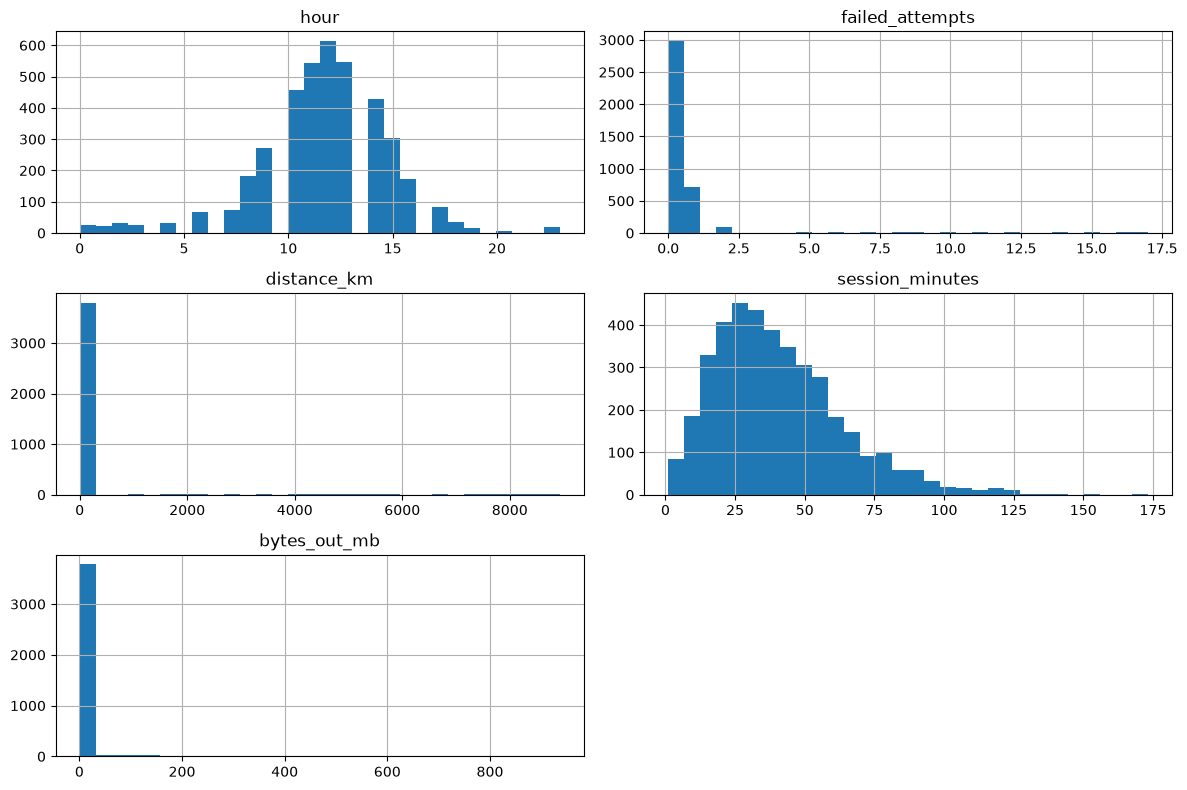

is_attack                0            1
hour             12.000000     2.000000
failed_attempts   0.000000    11.000000
distance_km      10.033474  4408.577160
session_minutes  37.992850     9.477511
bytes_out_mb      7.469846   149.085696


In [4]:
numeric_cols = [
    "hour", "failed_attempts", "distance_km",
    "session_minutes", "bytes_out_mb"
]
categorical_cols = ["user", "country", "device", "protocol"]

df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

print(df.groupby("is_attack")[numeric_cols].median().T)


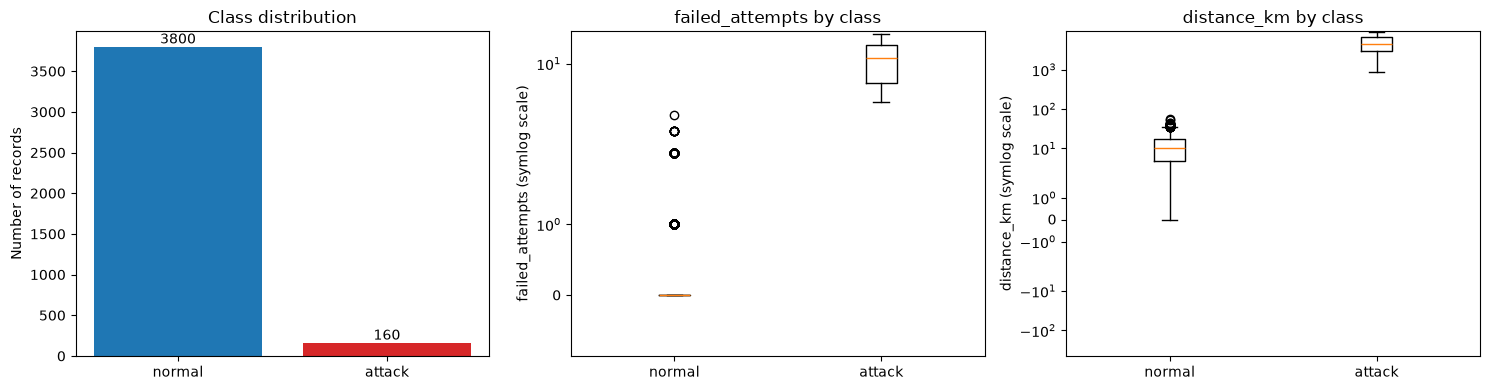

In [5]:
# 2b. Additional visualisations: class balance and key features by class
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

counts = df["is_attack"].map({0: "normal", 1: "attack"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["tab:blue", "tab:red"])
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Number of records")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom")

for ax, col in zip(axes[1:], ["failed_attempts", "distance_km"]):
    data = [df.loc[df["is_attack"] == 0, col], df.loc[df["is_attack"] == 1, col]]
    ax.boxplot(data)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["normal", "attack"])
    ax.set_yscale("symlog")
    ax.set_title(f"{col} by class")
    ax.set_ylabel(col + " (symlog scale)")

plt.tight_layout()
plt.show()

### How to interpret the exploratory results

Use the histograms and the class-wise median table to identify which variables differ most between normal and attack events.

- A strong shift in **failed attempts**, **distance**, **session duration**, or **outbound traffic** suggests that those variables contain useful anomaly evidence.
- Similar medians do **not** mean that a feature is useless. An anomaly may be caused by a rare **combination** of otherwise normal values.
- Because attacks are the minority class, overall accuracy would be misleading. Later comparisons therefore emphasize precision, recall, F1, false positives, and false negatives.

**Question to ask:** Which features appear individually unusual, and which may only become suspicious when combined with user, device, country, or protocol?


## 3. Shared train, validation and test split

The autoencoder is trained only on normal training events. Labels are retained exclusively for evaluation and threshold analysis.


In [6]:
train_df, temp_df = train_test_split(
    df, test_size=0.40, stratify=df["is_attack"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["is_attack"], random_state=SEED
)

normal_train_df = train_df[train_df["is_attack"] == 0].copy()
normal_val_df = val_df[val_df["is_attack"] == 0].copy()

print("Train:", train_df.shape, "Normal-only AE train:", normal_train_df.shape)
print("Validation:", val_df.shape, "Test:", test_df.shape)


Train: (2376, 10) Normal-only AE train: (2280, 10)
Validation: (792, 10) Test: (792, 10)


## 4. Model A — Isolation Forest

In [7]:
if_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ]
)

X_if_train = if_preprocessor.fit_transform(train_df[numeric_cols + categorical_cols])
X_if_test = if_preprocessor.transform(test_df[numeric_cols + categorical_cols])
y_test = test_df["is_attack"].to_numpy()

iso = IsolationForest(
    n_estimators=300,
    contamination=float(train_df["is_attack"].mean()),
    random_state=SEED,
    n_jobs=-1
)
iso.fit(X_if_train)

if_score = -iso.decision_function(X_if_test)
if_pred = (iso.predict(X_if_test) == -1).astype(int)

print(confusion_matrix(y_test, if_pred))
print(classification_report(y_test, if_pred, target_names=["Normal", "Attack"]))


[[759   1]
 [  0  32]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       760
      Attack       0.97      1.00      0.98        32

    accuracy                           1.00       792
   macro avg       0.98      1.00      0.99       792
weighted avg       1.00      1.00      1.00       792



Isolation Forest flagged 33 of 792 test records (4.17%).
True attacks in the test set: 32 (4.04%)


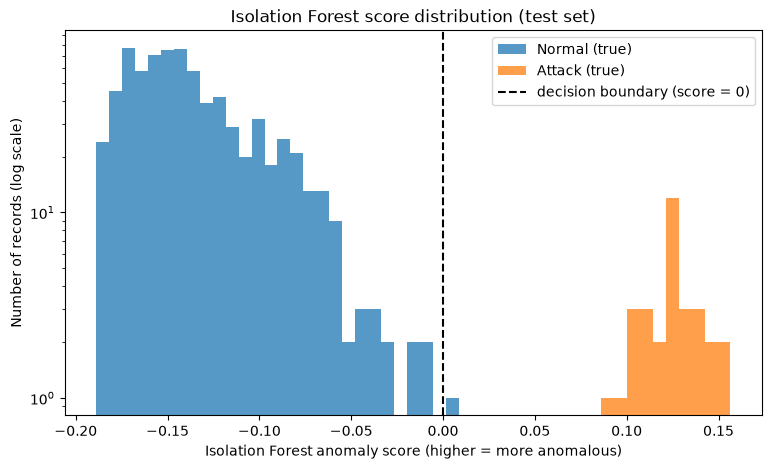

,if_score
count,792.000
mean,-0.126
std,0.062
min,-0.189
25%,-0.161
50%,-0.143
75%,-0.111
max,0.156


In [8]:
# 4a. Isolation Forest: score distribution and summary
n_flagged = int(if_pred.sum())
print(f"Isolation Forest flagged {n_flagged} of {len(if_pred)} test records ({n_flagged / len(if_pred):.2%}).")
print(f"True attacks in the test set: {int(y_test.sum())} ({y_test.mean():.2%})")

bins = np.linspace(if_score.min(), if_score.max(), 50)
plt.figure(figsize=(9, 5))
plt.hist(if_score[y_test == 0], bins=bins, alpha=0.75, label="Normal (true)")
plt.hist(if_score[y_test == 1], bins=bins, alpha=0.75, label="Attack (true)")
plt.axvline(0.0, color="black", linestyle="--", label="decision boundary (score = 0)")
plt.yscale("log")
plt.xlabel("Isolation Forest anomaly score (higher = more anomalous)")
plt.ylabel("Number of records (log scale)")
plt.title("Isolation Forest score distribution (test set)")
plt.legend()
plt.show()

display(pd.Series(if_score, name="if_score").describe().round(3).to_frame())

### Reading the Isolation Forest output

The confusion matrix follows this layout:

| | Predicted normal | Predicted attack |
|---|---:|---:|
| **Actually normal** | True negatives | False positives |
| **Actually attack** | False negatives | True positives |

Interpret the classification report as follows:

- **Attack precision:** among all alerts raised by Isolation Forest, how many were real attacks?
- **Attack recall:** among all real attacks, how many were detected?
- **Attack F1:** balance between precision and recall.
- **False positives:** normal events that would unnecessarily consume analyst time.
- **False negatives:** attacks that would remain undetected.

Isolation Forest is especially effective when an event is isolated in the transformed feature space, for example an extreme distance, many failed attempts, or a rare combination of one-hot encoded categories.


## 5. Model B — Autoencoder with categorical embeddings

Each categorical field is mapped to a trainable embedding. The decoder reconstructs:

- standardized numeric values using mean squared error;
- each categorical field using a softmax output.

The anomaly score combines numeric reconstruction error and categorical negative log likelihood.


In [9]:
# Numeric scaling
num_scaler = StandardScaler()
num_scaler.fit(normal_train_df[numeric_cols])

# Category encoders fitted on the full training partition, with an explicit unknown token
category_maps = {}
category_sizes = {}
for col in categorical_cols:
    values = sorted(train_df[col].astype(str).unique().tolist())
    category_maps[col] = {value: i + 1 for i, value in enumerate(values)}  # 0 = unknown
    category_sizes[col] = len(values) + 1

def prepare_ae_frame(frame):
    numeric = num_scaler.transform(frame[numeric_cols]).astype("float32")
    inputs = {"numeric": numeric}
    targets = {"numeric_out": numeric}
    for col in categorical_cols:
        indices = frame[col].astype(str).map(category_maps[col]).fillna(0).astype("int32").to_numpy()
        inputs[col] = indices
        targets[f"{col}_out"] = indices
    return inputs, targets

ae_train_inputs, ae_train_targets = prepare_ae_frame(normal_train_df)
ae_val_inputs, ae_val_targets = prepare_ae_frame(normal_val_df)
ae_test_inputs, ae_test_targets = prepare_ae_frame(test_df)


In [10]:
# Inputs
numeric_input = layers.Input(shape=(len(numeric_cols),), name="numeric")
model_inputs = {"numeric": numeric_input}
parts = [numeric_input]

for col in categorical_cols:
    inp = layers.Input(shape=(), dtype="int32", name=col)
    model_inputs[col] = inp
    emb_dim = min(8, max(2, int(np.ceil(np.sqrt(category_sizes[col])))))
    emb = layers.Embedding(category_sizes[col], emb_dim, name=f"{col}_embedding")(inp)
    parts.append(layers.Flatten()(emb))

combined = layers.Concatenate(name="combined_features")(parts)
hidden = layers.Dense(32, activation="relu")(combined)
latent = layers.Dense(8, activation="relu", name="behavior_embedding")(hidden)
decoded = layers.Dense(32, activation="relu")(latent)

outputs = {
    "numeric_out": layers.Dense(len(numeric_cols), name="numeric_out")(decoded)
}
for col in categorical_cols:
    outputs[f"{col}_out"] = layers.Dense(
        category_sizes[col], activation="softmax", name=f"{col}_out"
    )(decoded)

autoencoder = keras.Model(inputs=model_inputs, outputs=outputs)
encoder = keras.Model(inputs=model_inputs, outputs=latent)

losses = {"numeric_out": "mse"}
loss_weights = {"numeric_out": 1.0}
for col in categorical_cols:
    losses[f"{col}_out"] = "sparse_categorical_crossentropy"
    loss_weights[f"{col}_out"] = 0.35

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=losses,
    loss_weights=loss_weights
)
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country             │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ protocol            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_embedding      │ (None, 3)         │         18 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_embedding   │ (None, 3)         │         21 │ country[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_embedding    │ (None, 3)         │         21 │ device[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ protocol_embedding  │ (None, 2)         │          8 │ protocol[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3)         │          0 │ user_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3)         │          0 │ country_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3)         │          0 │ device_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 2)         │          0 │ protocol_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 16)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        544 │ combined_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ behavior_embedding  │ (None, 8)         │        264 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        288 │ behavior_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_out (Dense) │ (None, 7)         │        231 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_out (Dense)  │ (None, 7)         │        231 │ dense_1[0][0]   

 Total params: 2,121 (8.29 KB)

 Trainable params: 2,121 (8.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - country_out_loss: 1.8510 - device_out_loss: 1.9155 - loss: 3.4113 - numeric_out_loss: 0.9784 - protocol_out_loss: 1.4177 - user_out_loss: 1.7667 - val_country_out_loss: 1.7636 - val_device_out_loss: 1.8681 - val_loss: 3.3671 - val_numeric_out_loss: 0.9936 - val_protocol_out_loss: 1.3939 - val_user_out_loss: 1.7556
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - country_out_loss: 1.6611 - device_out_loss: 1.8090 - loss: 3.2065 - numeric_out_loss: 0.9026 - protocol_out_loss: 1.3731 - user_out_loss: 1.7394 - val_country_out_loss: 1.5168 - val_device_out_loss: 1.7409 - val_loss: 3.1329 - val_numeric_out_loss: 0.9189 - val_protocol_out_loss: 1.3448 - val_user_out_loss: 1.7235
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - country_out_loss: 1.3424 - device_out_loss: 1.6436 - loss: 2.9267 - numeric_out_loss: 0.8253 - protocol_out_loss: 1.3179 - user_out_loss: 1.7000 - val_country_out_loss: 1.0985 - val_device_out_loss: 1.5289 - val

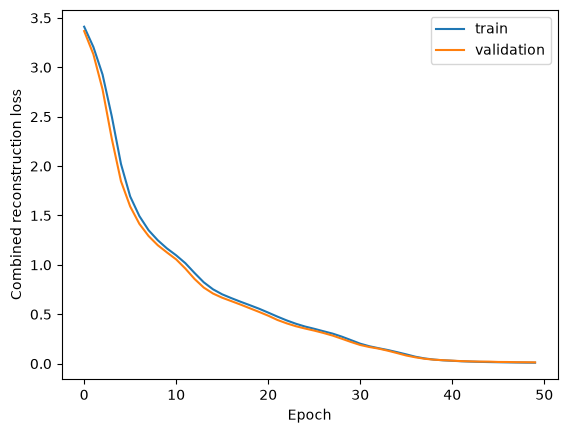

In [11]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )
]

history = autoencoder.fit(
    ae_train_inputs,
    ae_train_targets,
    validation_data=(ae_val_inputs, ae_val_targets),
    epochs=50,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Combined reconstruction loss")
plt.legend()
plt.show()


### Interpreting the training curve

Compare the training and validation reconstruction losses:

- Both curves decreasing suggests that the autoencoder is learning regular behavior.
- A validation curve that stops improving while training loss continues to fall indicates possible overfitting.
- A large persistent gap between the curves suggests that the model may not generalize well to unseen normal behavior.
- Early stopping restores the weights from the best validation epoch, so the final model is not necessarily the model from the last displayed epoch.

The absolute loss value is less important than stable convergence and similar behavior on the training and validation sets.


In [12]:
def ae_anomaly_scores(model, inputs, targets):
    predictions = model.predict(inputs, verbose=0)
    numeric_error = np.mean(
        np.square(targets["numeric_out"] - predictions["numeric_out"]), axis=1
    )

    categorical_error = np.zeros(len(numeric_error), dtype="float32")
    eps = 1e-8
    for col in categorical_cols:
        true_idx = targets[f"{col}_out"].astype(int)
        probs = predictions[f"{col}_out"]
        categorical_error += -np.log(probs[np.arange(len(true_idx)), true_idx] + eps)

    categorical_error /= len(categorical_cols)
    return numeric_error + 0.35 * categorical_error

normal_val_score = ae_anomaly_scores(autoencoder, ae_val_inputs, ae_val_targets)
ae_score = ae_anomaly_scores(autoencoder, ae_test_inputs, ae_test_targets)

threshold = np.percentile(normal_val_score, 99)
ae_pred = (ae_score > threshold).astype(int)

print("AE threshold:", threshold)
print(confusion_matrix(y_test, ae_pred))
print(classification_report(y_test, ae_pred, target_names=["Normal", "Attack"]))


AE threshold: 0.038876705
[[754   6]
 [  0  32]]
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       760
      Attack       0.84      1.00      0.91        32

    accuracy                           0.99       792
   macro avg       0.92      1.00      0.96       792
weighted avg       0.99      0.99      0.99       792



Threshold (99th percentile of normal validation scores): 0.0389
Autoencoder flagged 38 of 792 test records (4.80%).


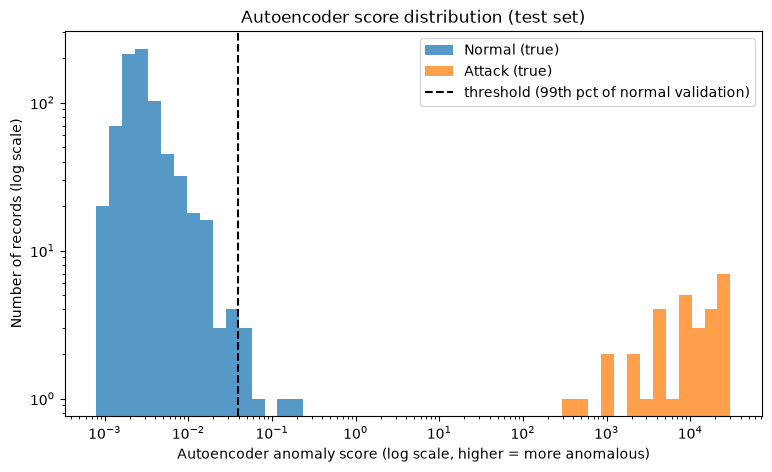

In [13]:
# 5a. Autoencoder: score distribution and threshold
print(f"Threshold (99th percentile of normal validation scores): {threshold:.4f}")
n_flagged_ae = int(ae_pred.sum())
print(f"Autoencoder flagged {n_flagged_ae} of {len(ae_pred)} test records ({n_flagged_ae / len(ae_pred):.2%}).")

positive = ae_score[ae_score > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 50)
plt.figure(figsize=(9, 5))
plt.hist(ae_score[y_test == 0], bins=bins, alpha=0.75, label="Normal (true)")
plt.hist(ae_score[y_test == 1], bins=bins, alpha=0.75, label="Attack (true)")
plt.axvline(threshold, color="black", linestyle="--", label="threshold (99th pct of normal validation)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Autoencoder anomaly score (log scale, higher = more anomalous)")
plt.ylabel("Number of records (log scale)")
plt.title("Autoencoder score distribution (test set)")
plt.legend()
plt.show()

### Reading the autoencoder output

The autoencoder is trained only on normal events. It assigns a high anomaly score when it reconstructs an event poorly.

The score combines:

- numeric reconstruction error; and
- categorical reconstruction surprise from user, country, device, and protocol.

The threshold is the 99th percentile of reconstruction scores from normal validation events. Therefore, approximately 1% of validation-normal behavior is expected to exceed the threshold even without an attack.

Interpretation:

- **High recall with low precision:** sensitive detector, but many unnecessary alerts.
- **High precision with low recall:** conservative detector that misses more attacks.
- **Many false positives:** threshold may be too low or normal behavior may be diverse.
- **Many false negatives:** threshold may be too high or attacks may resemble normal behavior.

Changing the percentile directly changes the operational trade-off: lower percentiles raise more alerts; higher percentiles raise fewer alerts.


## 6. Quantitative comparison

In [14]:
def metric_row(name, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average="binary", zero_division=0
    )
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        "model": name,
        "detected_anomalies": int(pred.sum()),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": int(fp),
        "false_negatives": int(fn)
    }

comparison = pd.DataFrame([
    metric_row("Isolation Forest", if_pred),
    metric_row("Autoencoder + embeddings", ae_pred)
]).set_index("model")

display(comparison.round(3))

agreement = np.mean(if_pred == ae_pred)
print(f"Agreement rate: {agreement:.2%}")
print("Both:", int(np.sum((if_pred == 1) & (ae_pred == 1))))
print("Isolation Forest only:", int(np.sum((if_pred == 1) & (ae_pred == 0))))
print("Autoencoder only:", int(np.sum((if_pred == 0) & (ae_pred == 1))))


,detected_anomalies,precision,recall,f1,false_positives,false_negatives
model,,,,,,
Isolation Forest,33,0.970,1.0,0.985,1,0
Autoencoder + embeddings,38,0.842,1.0,0.914,6,0


Agreement rate: 99.37%
Both: 33
Isolation Forest only: 0
Autoencoder only: 5


### How to compare the two methods

Use the table to answer different operational questions rather than declaring one universal winner:

- Prefer higher **recall** when missing an attack is the greatest risk.
- Prefer higher **precision** when analyst workload and alert fatigue are the main constraints.
- Prefer higher **F1** when precision and recall are equally important.
- Compare **false positives** and **false negatives** directly because they represent different operational costs.

The agreement statistics indicate complementarity:

- **Both models:** strongest candidates for analyst review.
- **Isolation Forest only:** globally isolated observations that the autoencoder reconstructed acceptably.
- **Autoencoder only:** observations that violate learned behavioral relationships even if no single feature is extreme.

A high agreement rate does not automatically mean better detection; it only means that the models often make the same decision.


In [15]:
# Automatic interpretation of the comparison table
best_precision = comparison["precision"].idxmax()
best_recall = comparison["recall"].idxmax()
best_f1 = comparison["f1"].idxmax()
fewest_fp = comparison["false_positives"].idxmin()
fewest_fn = comparison["false_negatives"].idxmin()

print("RESULT INTERPRETATION")
print("- Highest precision:", best_precision)
print("- Highest recall:", best_recall)
print("- Highest F1:", best_f1)
print("- Fewest false positives:", fewest_fp)
print("- Fewest false negatives:", fewest_fn)

if best_precision == best_recall == best_f1:
    print(f"\n{best_f1} is strongest on the main summary metrics for this run.")
else:
    print("\nNo single model dominates every criterion. Select a model according to the operational cost of false alerts versus missed attacks.")

print("\nRecommended triage rule:")
print("1. Prioritize events detected by both models.")
print("2. Review model-disagreement events manually.")
print("3. Treat events rejected by both as lower priority, not guaranteed benign.")


RESULT INTERPRETATION
- Highest precision: Isolation Forest
- Highest recall: Isolation Forest
- Highest F1: Isolation Forest
- Fewest false positives: Isolation Forest
- Fewest false negatives: Isolation Forest

Isolation Forest is strongest on the main summary metrics for this run.

Recommended triage rule:
1. Prioritize events detected by both models.
2. Review model-disagreement events manually.
3. Treat events rejected by both as lower priority, not guaranteed benign.


## 7. Original feature space versus behavioral embedding space

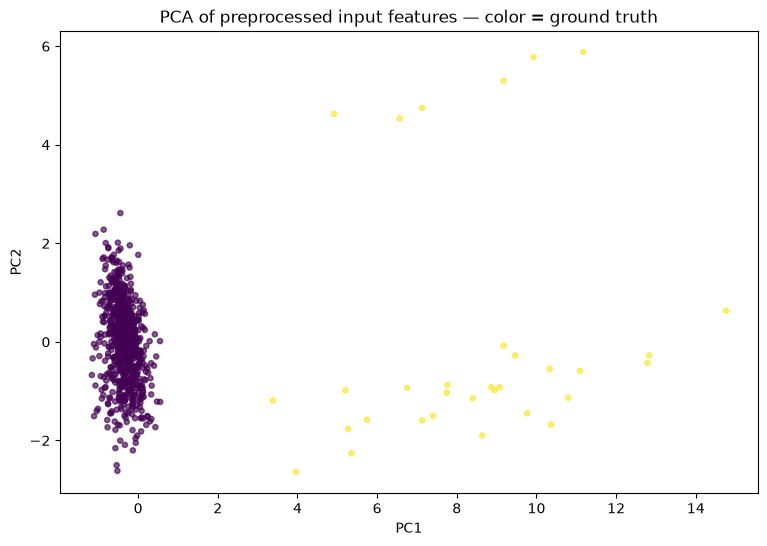

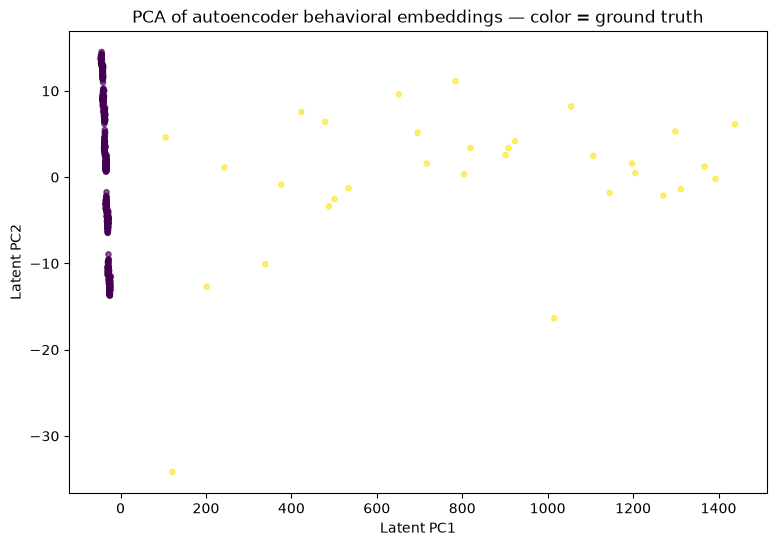

In [16]:
# PCA of Isolation Forest input space
pca_original = PCA(n_components=2, random_state=SEED)
xy_original = pca_original.fit_transform(X_if_test)

# PCA of learned latent behavioral embeddings
latent_vectors = encoder.predict(ae_test_inputs, verbose=0)
pca_latent = PCA(n_components=2, random_state=SEED)
xy_latent = pca_latent.fit_transform(latent_vectors)

plt.figure(figsize=(9, 6))
plt.scatter(xy_original[:, 0], xy_original[:, 1], c=y_test, s=14, alpha=0.65)
plt.title("PCA of preprocessed input features — color = ground truth")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(xy_latent[:, 0], xy_latent[:, 1], c=y_test, s=14, alpha=0.65)
plt.title("PCA of autoencoder behavioral embeddings — color = ground truth")
plt.xlabel("Latent PC1")
plt.ylabel("Latent PC2")
plt.show()


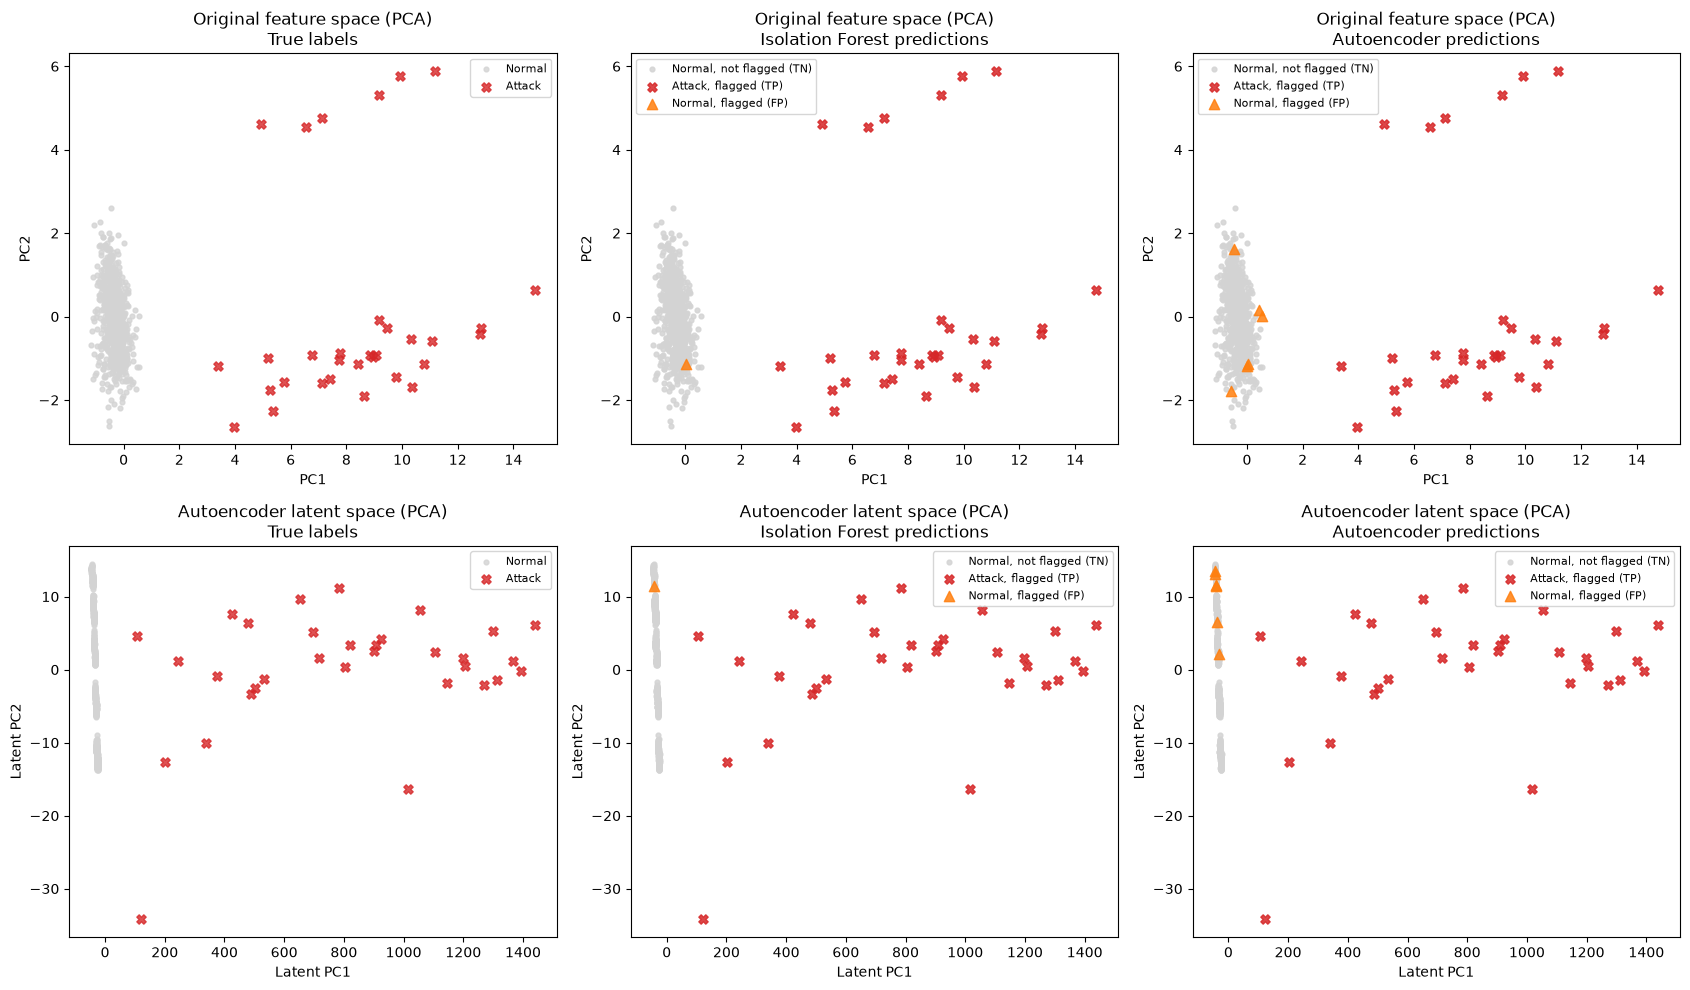

In [17]:
# 7a. Original-space and latent-space plots with truth, Isolation Forest and autoencoder outcomes
def outcome(y_true, y_pred):
    return np.select(
        [(y_true == 0) & (y_pred == 0), (y_true == 1) & (y_pred == 1),
         (y_true == 0) & (y_pred == 1), (y_true == 1) & (y_pred == 0)],
        ["TN", "TP", "FP", "FN"],
        default="TN"
    )

style = {
    "TN": dict(c="lightgray", marker="o", s=12, label="Normal, not flagged (TN)"),
    "TP": dict(c="tab:red", marker="X", s=45, label="Attack, flagged (TP)"),
    "FP": dict(c="tab:orange", marker="^", s=55, label="Normal, flagged (FP)"),
    "FN": dict(c="tab:blue", marker="s", s=55, label="Attack, missed (FN)"),
}
truth_style = [(0, "lightgray", "o", 12, "Normal"), (1, "tab:red", "X", 45, "Attack")]

spaces = [("Original feature space (PCA)", xy_original, "PC1", "PC2"),
          ("Autoencoder latent space (PCA)", xy_latent, "Latent PC1", "Latent PC2")]
panels = [("True labels", None), ("Isolation Forest predictions", if_pred), ("Autoencoder predictions", ae_pred)]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for r, (space_name, xy, xl, yl) in enumerate(spaces):
    for c, (panel_name, pred) in enumerate(panels):
        ax = axes[r, c]
        if pred is None:
            for lab, col, mk, sz, txt in truth_style:
                m = y_test == lab
                ax.scatter(xy[m, 0], xy[m, 1], c=col, marker=mk, s=sz, label=txt, alpha=0.8)
        else:
            oc = outcome(y_test, pred)
            for key, st in style.items():
                m = oc == key
                if m.any():
                    ax.scatter(xy[m, 0], xy[m, 1], c=st["c"], marker=st["marker"], s=st["s"],
                               label=st["label"], alpha=0.85)
        ax.set_title(f"{space_name}\n{panel_name}")
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

### Interpreting the PCA visualizations

PCA compresses a high-dimensional representation into two dimensions. Therefore, these plots are diagnostic aids rather than proof of model quality.

- Clear separation between normal and attack points suggests that the representation contains useful anomaly structure.
- Overlap is expected because two principal components discard information.
- Better separation in the latent plot suggests that the autoencoder has learned a useful behavioral representation.
- Poor separation in the latent plot does not necessarily mean poor detection because the anomaly score is based on reconstruction error, not PCA distance.

Use the quantitative metrics as the primary evaluation and the plots to explain patterns.


## 8. Inspect model disagreements

In [18]:
results = test_df.copy()
results["if_score"] = if_score
results["if_pred"] = if_pred
results["ae_score"] = ae_score
results["ae_pred"] = ae_pred
results["models_agree"] = results["if_pred"] == results["ae_pred"]

disagreements = results[~results["models_agree"]].copy()
display(disagreements.sort_values(["ae_score", "if_score"], ascending=False).head(15))


,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,is_attack,if_score,if_pred,ae_score,ae_pred,models_agree
870,admin01,IL,admin_workstation,VPN,16,0,4.156354,12.158062,3.901917,0,-0.062123,0,0.131464,1,False
2688,admin01,IL,admin_workstation,HTTPS,9,0,22.362931,93.213104,4.188047,0,-0.067464,0,0.060056,1,False
372,analyst02,IL,managed_laptop,HTTPS,10,1,31.692761,13.494365,40.451243,0,-0.100038,0,0.045375,1,False
567,admin01,IL,admin_workstation,VPN,8,0,5.496732,44.161504,12.741050,0,-0.070227,0,0.044727,1,False
2975,developer01,IL,developer_workstation,HTTPS,11,2,0.642864,23.068715,25.930824,0,-0.091810,0,0.043617,1,False


In [19]:
# 8a. Why do the models disagree? z-scores, category rarity and autoencoder score components
def ae_breakdown(rows):
    """Per-record autoencoder score components: numeric squared errors and categorical negative log-likelihoods."""
    pos = [test_df.index.get_loc(i) for i in rows.index]
    inputs = {k: v[pos] for k, v in ae_test_inputs.items()}
    targets = {k: v[pos] for k, v in ae_test_targets.items()}
    pred = autoencoder.predict(inputs, verbose=0)
    out = pd.DataFrame(index=rows.index)
    num_err = np.square(targets["numeric_out"] - pred["numeric_out"])
    for j, col in enumerate(numeric_cols):
        out[f"err_{col}"] = num_err[:, j]
    for col in categorical_cols:
        idx = targets[f"{col}_out"].astype(int)
        out[f"nll_{col}"] = -np.log(pred[f"{col}_out"][np.arange(len(idx)), idx] + 1e-8)
    return out.round(3)

dis = results[~results["models_agree"]].copy()
n_if_only = int(((dis["if_pred"] == 1) & (dis["ae_pred"] == 0)).sum())
n_ae_only = int(((dis["if_pred"] == 0) & (dis["ae_pred"] == 1)).sum())
print(f"{len(dis)} records where the models disagree (Isolation Forest only: {n_if_only}, Autoencoder only: {n_ae_only})")

if len(dis) > 0:
    mu = normal_train_df[numeric_cols].mean()
    sd = normal_train_df[numeric_cols].std()
    print("\nz-scores of numeric features relative to normal training behaviour:")
    display(((dis[numeric_cols] - mu) / sd).round(2))

    print("\nShare of normal training records that have the same categorical value (low = rare):")
    share = pd.DataFrame({
        col: dis[col].map(normal_train_df[col].value_counts(normalize=True)).fillna(0.0).round(3)
        for col in categorical_cols
    })
    display(share)

    print("\nAutoencoder score components (numeric squared error / categorical negative log-likelihood):")
    display(ae_breakdown(dis))

5 records where the models disagree (Isolation Forest only: 0, Autoencoder only: 5)

z-scores of numeric features relative to normal training behaviour:


,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb
567,-1.62,-0.48,-0.70,0.08,0.73
2688,-1.21,-0.48,1.30,2.23,-0.83
372,-0.81,1.52,2.42,-1.26,5.78
2975,-0.40,3.52,-1.28,-0.84,3.14
870,1.62,-0.48,-0.86,-1.31,-0.88



Share of normal training records that have the same categorical value (low = rare):


,user,country,device,protocol
567,0.103,1.0,0.103,0.314
2688,0.103,1.0,0.103,0.607
372,0.203,1.0,0.651,0.607
2975,0.246,1.0,0.246,0.607
870,0.103,1.0,0.103,0.314



Autoencoder score components (numeric squared error / categorical negative log-likelihood):


,err_hour,err_failed_attempts,err_distance_km,err_session_minutes,err_bytes_out_mb,nll_user,nll_country,nll_device,nll_protocol
567,0.029,0.025,0.003,0.000,0.155,0.015,-0.0,0.004,0.006
2688,0.046,0.117,0.016,0.099,0.001,0.041,-0.0,0.004,0.002
372,0.000,0.025,0.000,0.008,0.187,0.010,-0.0,0.000,0.005
2975,0.004,0.176,0.001,0.021,0.010,0.005,-0.0,0.001,0.009
870,0.219,0.002,0.070,0.019,0.336,0.008,-0.0,0.004,0.015


### How to investigate disagreements

Disagreement records are the most informative cases for comparing the models.

For **Isolation Forest only** alerts, check whether one or more original features are extreme. The event may be globally isolated even though the autoencoder can reconstruct its overall pattern.

For **autoencoder only** alerts, check whether the event contains an unusual relationship such as:

- a familiar user with an unfamiliar device;
- a normal login hour from an unusual country;
- individually moderate values that form an abnormal behavioral combination.

For each disagreement, record:

1. which model raised the alert;
2. the strongest supporting evidence;
3. whether the event appears malicious, unusual but legitimate, or inconclusive;
4. whether an analyst should escalate, request more evidence, or close the alert.

Do not assume that either model is automatically correct. Ground truth is available here for evaluation, but in a real SOC the disagreement would require investigation.


### Supporting records for the human decision task

The next cell lists the three highest-scoring alerts raised by both models, the components of their autoencoder score, and all false positives of the test set. Use them in the student interpretation below.

In [20]:
# 9a. Supporting records for the human decision task: three high-scoring alerts
# The label (is_attack) is shown only to check the decision afterwards; the decision itself is made from the evidence.
both = results[(results["if_pred"] == 1) & (results["ae_pred"] == 1)].copy()
both["rank_sum"] = both["if_score"].rank(ascending=False) + both["ae_score"].rank(ascending=False)
top_alerts = both.sort_values("rank_sum").head(3)

show_cols = ["user", "country", "device", "protocol", "hour", "failed_attempts",
             "distance_km", "session_minutes", "bytes_out_mb", "if_score", "ae_score", "is_attack"]
print("Top three alerts flagged by both models (highest combined rank):")
display(top_alerts[show_cols].round(2))
print("\nAutoencoder score components for these alerts:")
display(ae_breakdown(top_alerts))

fp = results[(results["is_attack"] == 0) & ((results["if_pred"] == 1) | (results["ae_pred"] == 1))]
print(f"\nFalse positives in the test set: {len(fp)} "
      f"(flagged by Isolation Forest: {int(fp['if_pred'].sum())}, by autoencoder: {int(fp['ae_pred'].sum())})")
display(fp[show_cols].round(2))

Top three alerts flagged by both models (highest combined rank):


,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,if_score,ae_score,is_attack
1813,admin01,US,unknown,HTTPS,1,7,8543.95,14.14,314.67,0.14,27281.099609,1
656,analyst01,CN,mobile,SSH,23,7,7939.05,6.41,340.27,0.15,23547.339844,1
1556,analyst02,US,unmanaged_laptop,SSH,2,10,8230.76,4.34,438.21,0.14,25131.269531,1



Autoencoder score components for these alerts:


,err_hour,err_failed_attempts,err_distance_km,err_session_minutes,err_bytes_out_mb,nll_user,nll_country,nll_device,nll_protocol
1813,1052.206055,12970.603516,117583.062500,2605.023926,2162.329102,18.421,18.421,18.421,18.421
656,1174.766968,11985.005859,100663.671875,2420.618896,1460.400024,18.402,18.421,18.421,18.421
1556,1137.198975,12588.288086,107967.718750,2712.738037,1226.229004,-0.000,18.421,18.421,18.421



False positives in the test set: 6 (flagged by Isolation Forest: 1, by autoencoder: 6)


,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,if_score,ae_score,is_attack
567,admin01,IL,admin_workstation,VPN,8,0,5.50,44.16,12.74,-0.07,0.04,0
2688,admin01,IL,admin_workstation,HTTPS,9,0,22.36,93.21,4.19,-0.07,0.06,0
372,analyst02,IL,managed_laptop,HTTPS,10,1,31.69,13.49,40.45,-0.10,0.05,0
2962,admin01,IL,admin_workstation,SSH,10,0,12.19,78.74,43.70,0.00,0.19,0
2975,developer01,IL,developer_workstation,HTTPS,11,2,0.64,23.07,25.93,-0.09,0.04,0
870,admin01,IL,admin_workstation,VPN,16,0,4.16,12.16,3.90,-0.06,0.13,0


## 9. Student interpretation

Select at least three disagreement records and answer:

1. Which model raised the alert?
2. What evidence supports the alert?
3. Could the event be a legitimate exception?
4. Would you accept, challenge, or escalate the alert?
5. Which MITRE ATT&CK technique is most relevant?

## 10. Conclusion

Compare the models in terms of:

- precision and recall;
- false positives and false negatives;
- anomaly types detected;
- usefulness of behavioral embeddings;
- limitations of training only on synthetic or incomplete normal data.


## 9a. Disagreement analysis (5 records, all flagged only by the Autoencoder, all actually normal)

The models disagreed on 5 of 792 test records (agreement rate 99.37%). All five were raised only by the Autoencoder, and none by Isolation Forest only. Ground truth shows that all five are normal, so they are Autoencoder false positives.

| Record | Model | Evidence | Legitimate exception? | Decision | MITRE (if malicious) |
|---|---|---|---|---|---|
| idx 870 (admin01, VPN, hour 16, 3.9 MB out) | Autoencoder only (score 0.1315, highest of the group) | Largest error components are outbound bytes and hour; rare user (admin01 is about 10% of traffic) | Yes, an admin working at an unusual hour | Challenge | T1078 Valid Accounts |
| idx 2688 (admin01, HTTPS, 93 min session) | Autoencoder only (0.0601) | Session length +2.2 standard deviations; country IL, managed device | Yes, a long maintenance session | Challenge | T1078 Valid Accounts |
| idx 372 (analyst02, HTTPS, 40 MB out) | Autoencoder only (0.0454) | Outbound bytes +5.8 and distance +2.4 standard deviations; usual country and device | Probably, a large report or download | Escalate for low-priority verification (volume) | T1041 Exfiltration Over C2 Channel |
| idx 2975 (developer01, 2 failed attempts, 26 MB out) | Autoencoder only (0.0436) | Failed attempts +3.5 and bytes +3.1 standard deviations | Yes, a mistyped password followed by a data pull; 2 failures is not a brute-force pattern | Challenge and monitor | T1110 Brute Force (weak match) |
| idx 567 (admin01, VPN, hour 8) | Autoencoder only (0.0447, barely above threshold 0.0389) | Borderline score, no extreme feature | Yes | Close / challenge | none |

**Why Isolation Forest did not flag them:** each record is only mildly unusual in one or two numeric features and is not isolated in the full feature space. The Autoencoder is more sensitive to unusual combinations, especially for rare users, and its 99th-percentile threshold lets about 1% of normal records through as alerts.

## 9b. Human-AI decision task (three high-scoring alerts flagged by both models)

All three are true attacks according to the label. The label is used here only for verification; the decisions are justified from the evidence in the record.

**Alert 1 - idx 1813: admin01, US, unknown device, HTTPS, hour 1**
- Evidence: 7 failed attempts, 8,544 km from the usual location, unknown country and device, off-hours login, 315 MB sent out. The Autoencoder score is about 27,281, driven mostly by categories never seen in training.
- Decision: **Escalate.** A privileged account from a foreign location and an unmanaged device with a large outbound transfer suggests account takeover followed by data theft.
- False-positive explanation: an admin travelling abroad on personal equipment. This is unlikely given 7 failures and 315 MB.
- MITRE: T1110 Brute Force, T1078 Valid Accounts, T1041 Exfiltration Over C2 Channel.

**Alert 2 - idx 656: analyst01, CN, mobile, SSH, hour 23**
- Evidence: 7 failed attempts, 7,939 km away, SSH from a mobile device, a very short session (6.4 min) and 340 MB out. The country and device were not seen in normal training data.
- Decision: **Escalate.** Repeated failures followed by a short session with a large transfer match credential guessing and fast data collection.
- False-positive explanation: a legitimate analyst abroad on a mobile network. SSH from mobile plus the volume make this unlikely.
- MITRE: T1110, T1078, T1041.

**Alert 3 - idx 1556: analyst02, US, unmanaged laptop, SSH, hour 2**
- Evidence: 10 failed attempts (the highest in the sample), 8,231 km, an unmanaged laptop, a 4.3 min session and 438 MB out (the largest transfer).
- Decision: **Escalate (highest priority).** A strong brute-force signature followed by a fast, large exfiltration.
- False-positive explanation: a personal laptop on a business trip. This would not explain 10 failures and 438 MB in under 5 minutes.
- MITRE: T1110, T1078, T1041.

**Human role:** the models rank and flag. The analyst verifies with the user (is the person travelling?), identity-provider logs and the destination of the transfer, then decides on containment such as a credential reset or blocking the session.


## 10a. Conclusion (based on the actual results of this run)

**1. Which model performed better, and by which measure?**
On this dataset and with the current parameters, **Isolation Forest performed better**: F1 = 0.985 versus 0.914 for the Autoencoder, and precision = 0.970 versus 0.842. Both reached recall = 1.00 (32 of 32 attacks, 0 false negatives), so the difference lies only in precision. This is one run on synthetic data and is not a general claim that one model is better.

**2. Which model produced fewer false positives?**
Isolation Forest: **1 false positive** versus **6** for the Autoencoder. The Autoencoder threshold is the 99th percentile of normal validation scores, which by design lets about 1% of normal records through as alerts. In a SOC this adds analyst workload and alert fatigue.

**3. What types of anomalies were unique to each model?**
Isolation Forest had no unique detections. The Autoencoder had 5 unique alerts, all false positives: normal logins from familiar countries and managed devices that were unusual in a combination of features (a rare user such as admin01 with a long session or unusual hour and volume, or a larger-than-usual transfer for an analyst). The Autoencoder also reacts very strongly to categories never seen in training (country, device, protocol), which produced very high scores for the real attacks. Here its unique alerts were noise, not new attacks.

**4. Did embeddings improve behavioral separation?**
Not measurably here. The attacks are already clearly separated in the PCA of the original feature space because the synthetic attacks are extreme in several features at once (distance, failed attempts, outbound bytes). The latent space preserves this separation, with normal records in a tight cluster and attacks far from it, but the false positives still sit at the edge of the normal cluster. Overlap or separation in a 2D projection is not proof of model quality, because PCA compresses information. Embeddings may matter more on larger and more subtle datasets.

**5. Why should a SOC analyst avoid relying on one model alone?**
The models see the data differently: Isolation Forest finds numeric outliers, while the Autoencoder learns normal behavioral patterns including combinations of categories. Alerts flagged by both models (33 here) are the strongest candidates for escalation, and disagreements (5 here) show where human context is needed. Either model can be wrong, and neither can know whether an admin is genuinely travelling. The decision remains with the human.

**Limitations:** the data is synthetic and the attacks are easy to separate, so the near-perfect recall would probably not hold on real traffic. The Isolation Forest `contamination` parameter was set from the attack share in the training labels, which uses label information a real SOC would not have. Autoencoder training is not seeded, so its numbers vary slightly between runs (the analysis above refers to this run).
